Importing the dependencies

In [68]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


In [69]:
#loading the data into a pandas df
car_data=pd.read_csv('/content/Car details v3.csv')

In [70]:
car_data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [71]:
car_data.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,221
engine,221


In [72]:
car_data.shape

(8128, 13)

In [73]:
car_data=car_data.dropna()

In [74]:
car_data.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,0
engine,0


In [75]:
car_data['fuel'].value_counts()

,count
fuel,
Diesel,4299
Petrol,3520
CNG,52
LPG,35


In [76]:
car_data.head(100)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
5,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
6,Maruti Wagon R LXI DUO BSIII,2007,96000,175000,LPG,Individual,Manual,First Owner,17.3 km/kg,1061 CC,57.5 bhp,"7.8@ 4,500(kgm@ rpm)",5.0
7,Maruti 800 DX BSII,2001,45000,5000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
8,Toyota Etios VXD,2011,350000,90000,Diesel,Individual,Manual,First Owner,23.59 kmpl,1364 CC,67.1 bhp,170Nm@ 1800-2400rpm,5.0
9,Ford Figo Diesel Celebration Edition,2013,200000,169000,Diesel,Individual,Manual,First Owner,20.0 kmpl,1399 CC,68.1 bhp,160Nm@ 2000rpm,5.0


In [77]:
car_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7906 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           7906 non-null   object 
 1   year           7906 non-null   int64  
 2   selling_price  7906 non-null   int64  
 3   km_driven      7906 non-null   int64  
 4   fuel           7906 non-null   object 
 5   seller_type    7906 non-null   object 
 6   transmission   7906 non-null   object 
 7   owner          7906 non-null   object 
 8   mileage        7906 non-null   object 
 9   engine         7906 non-null   object 
 10  max_power      7906 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7906 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 864.7+ KB


In [78]:
pd.options.display.max_rows=1000

In [79]:
car_data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [80]:
car_data['seller_type'].value_counts()

,count
seller_type,
Individual,6563
Dealer,1107
Trustmark Dealer,236


In [81]:
car_data['transmission'].value_counts()

,count
transmission,
Manual,6865
Automatic,1041


In [82]:
car_data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [83]:
car_data['owner'].value_counts()

,count
owner,
First Owner,5215
Second Owner,2016
Third Owner,510
Fourth & Above Owner,160
Test Drive Car,5


In [84]:
car_data.replace({'fuel':{"Diesel":0,"Petrol":1,"CNG":2,"LPG":3}},inplace=True)
car_data.replace({'seller_type':{"Individual":0,"Dealer":1,"Trustmark Dealer":2}},inplace=True)
car_data.replace({"transmission":{"Manual":0,"Automatic":1}},inplace=True)
car_data.replace({'owner':{"First Owner":0,"Second Owner":1,"Third Owner":2,"Fourth & Above Owner":3,"Test Drive Car":4}},inplace=True)

/tmp/ipykernel_2756/1296341556.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  car_data.replace({'fuel':{"Diesel":0,"Petrol":1,"CNG":2,"LPG":3}},inplace=True)
/tmp/ipykernel_2756/1296341556.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  car_data.replace({'seller_type':{"Individual":0,"Dealer":1,"Trustmark Dealer":2}},inplace=True)
/tmp/ipykernel_2756/1296341556.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.i

In [85]:
car_data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,0,0,0,0,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,0,0,0,1,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,1,0,0,2,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,0,0,0,0,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,1,0,0,0,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [86]:
#separate the data into features and labels
X=car_data.drop(columns=['name','mileage','engine','max_power','torque','seats','selling_price'])
Y=car_data['selling_price']

In [87]:
print(X)

      year  km_driven  fuel  seller_type  transmission  owner
0     2014     145500     0            0             0      0
1     2014     120000     0            0             0      1
2     2006     140000     1            0             0      2
3     2010     127000     0            0             0      0
4     2007     120000     1            0             0      0
...    ...        ...   ...          ...           ...    ...
8123  2013     110000     1            0             0      0
8124  2007     119000     0            0             0      3
8125  2009     120000     0            0             0      0
8126  2013      25000     0            0             0      0
8127  2013      25000     0            0             0      0

[7906 rows x 6 columns]


In [88]:
print(Y)

0       450000
1       370000
2       158000
3       225000
4       130000
         ...  
8123    320000
8124    135000
8125    382000
8126    290000
8127    290000
Name: selling_price, Length: 7906, dtype: int64


In [89]:
#split the data into training and testing data
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=3)

In [90]:
print(X.shape,X_train.shape,X_test.shape)

(7906, 6) (6324, 6) (1582, 6)


In [91]:
#laod the linearegression model
model=LinearRegression()

In [92]:
#train the model
model.fit(X_train,Y_train)

LinearRegression()

In [93]:
#Evaluate the model
#prediction on training data
training_data_prediction=model.predict(X_train)
#prediction on testing data
testing_data_prediction=model.predict(X_test)

In [94]:
#R-squared Error on training data
error_score_Train=r2_score(Y_train,training_data_prediction)
print("R-squared Error: ",error_score)

R-squared Error:  0.4776382298946087


In [95]:
# R - squared error on testing data
error_score_Test=r2_score(Y_test,testing_data_prediction)
print("R-squared Error: ",error_score)

R-squared Error:  0.4776382298946087


In [96]:
#mean absolute error on test data
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(Y_test,testing_data_prediction)
print("Mean Absolute Error: ",mae)

Mean Absolute Error:  315159.33736781985


In [97]:
#mean absoluter error on train data
mae=mean_absolute_error(Y_train,training_data_prediction)
print("Mean Absolute Error: ",mae)
#

Mean Absolute Error:  312786.4090328077


In [98]:
#

### Building a Predictive System

This section demonstrates how to use the trained model to predict the selling price of a new car. We need to provide the car's features as input, ensure they are in the correct numerical format, and then pass them to the model.

In [99]:

input_data = (2017,35000,1,0,0,0)

# Define column names based on the X_train DataFrame
feature_names = ['year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

# Convert the input data to a Pandas DataFrame with feature names
input_df = pd.DataFrame([input_data], columns=feature_names)

# Make the prediction
prediction = model.predict(input_df)

print(f"The predicted selling price for the car is: {prediction[0]:,.2f}")

The predicted selling price for the car is: 467,385.74


In [100]:
print(X_train)

      year  km_driven  fuel  seller_type  transmission  owner
4465  2018      35000     0            0             0      0
5316  2007     120000     0            0             0      3
4220  2016      68089     1            2             1      0
7074  2012     120000     0            0             0      1
477   2013      60000     0            0             0      1
...    ...        ...   ...          ...           ...    ...
7296  2010     116000     0            0             0      0
1717  2016      56494     1            2             0      0
3426  2018       2000     0            1             1      0
1738  2009      80000     0            0             0      2
6167  2019      20000     1            1             1      0

[6324 rows x 6 columns]


In [101]:
X_train.iloc[[4465]]

,year,km_driven,fuel,seller_type,transmission,owner
7917,2017,35000,1,0,0,0


In [102]:
car_data.iloc[4465]

,4599
name,Honda City i VTEC V
year,2015
selling_price,525000
km_driven,120000
fuel,1
seller_type,0
transmission,0
owner,1
mileage,17.4 kmpl
engine,1497 CC


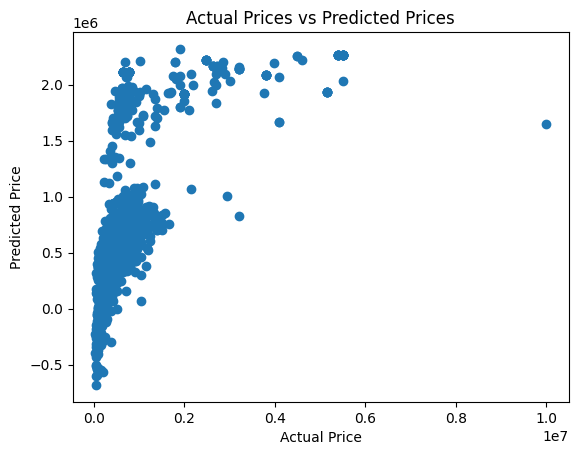

In [104]:
#visual representation actual vs predicted
plt.scatter(Y_test,testing_data_prediction)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual Prices vs Predicted Prices")
plt.show()